In [1]:
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import LocallyLinearEmbedding, MDS

In [2]:
mnist = fetch_openml("mnist_784", as_frame=False)

In [3]:
X, y = mnist.data, mnist.target

In [10]:
x_top_5000 = X[:5_000]
y_top_5000 = y[:5_000].astype(np.uint8)

In [5]:
t_sne = TSNE()
x_tsne = t_sne.fit_transform(x_top_5000)

In [6]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_top_5000)

In [7]:
lle = LocallyLinearEmbedding(n_components=2)
x_lle = pca.fit_transform(x_top_5000)

In [8]:
mds = LocallyLinearEmbedding(n_components=2)
x_mds = mds.fit_transform(x_top_5000)

In [11]:
def plot_embedding(X_reduced, y, title):
    plt.figure(figsize=(10, 8))

    scatter = plt.scatter(
        X_reduced[:, 0],
        X_reduced[:, 1],
        c=y,
        cmap="tab10",
        s=5,
        alpha=0.6
    )

    plt.colorbar(scatter, ticks=range(10))
    plt.title(title)
    plt.show()

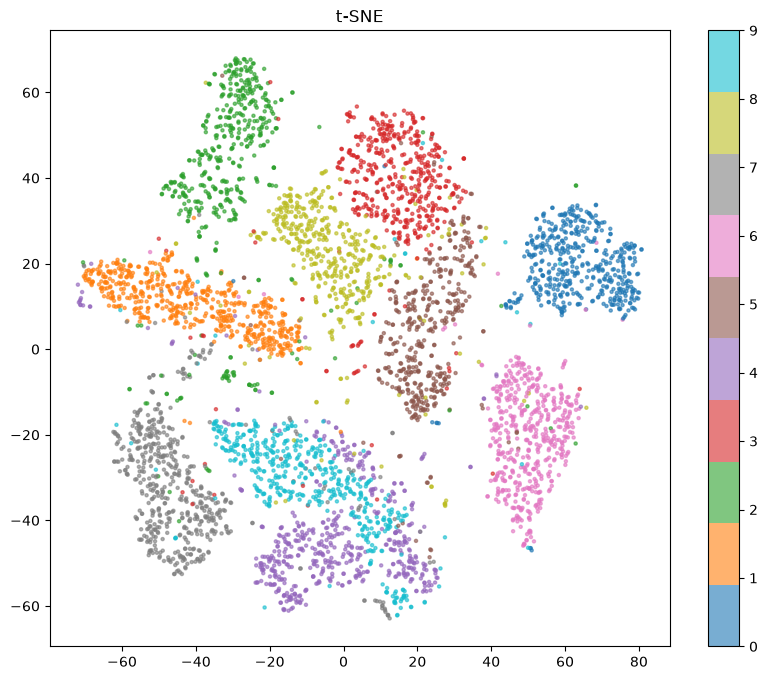

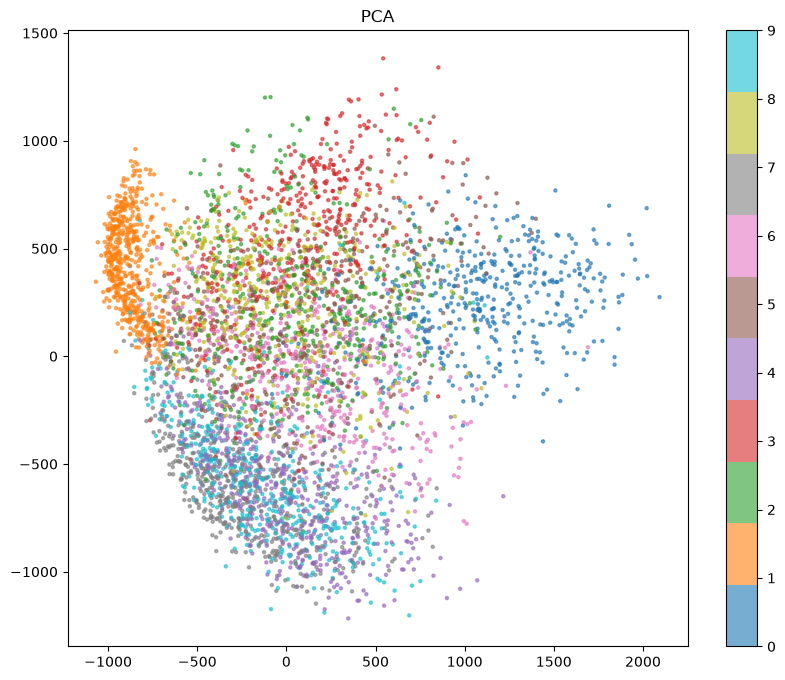

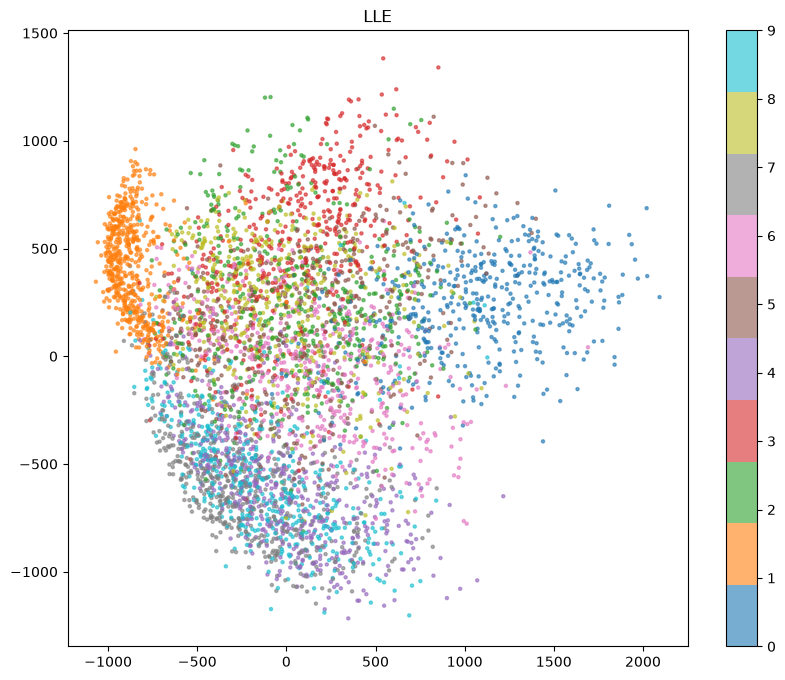

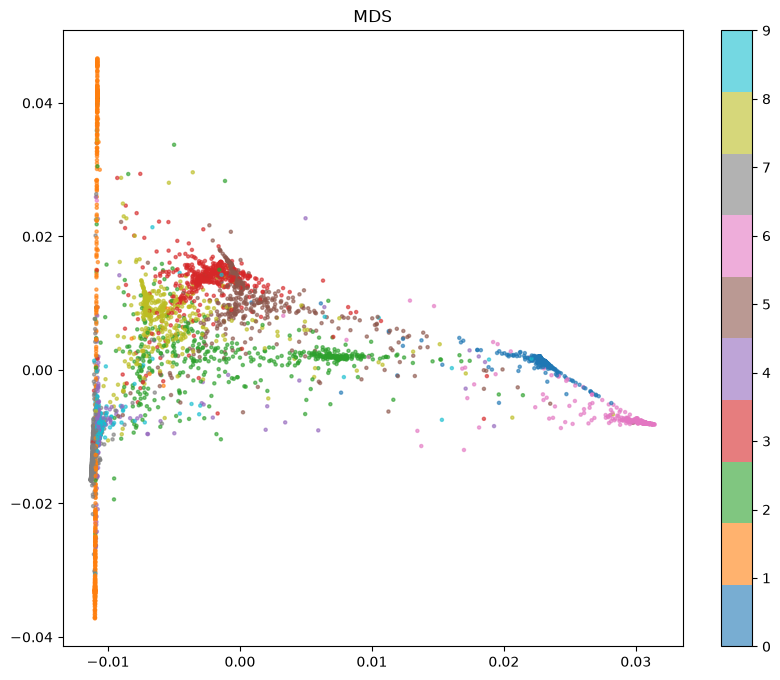

In [14]:
plot_embedding(x_tsne, y_top_5000, "t-SNE")
plot_embedding(x_pca, y_top_5000, "PCA")
plot_embedding(x_lle, y_top_5000, "LLE")
plot_embedding(x_mds, y_top_5000, "MDS")